# Analyse exploratoire
## 1. Import de la base nettoyée

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()
df = pd.read_csv("../data/etudiants_propre.csv")
print(df.shape)

(500, 14)


## 2. Indicateurs généraux

In [2]:
print("Moyenne générale :", round(df["moyenne"].mean(), 2))
print("Meilleure moyenne :", df["moyenne"].max())
print("Plus faible moyenne :", df["moyenne"].min())
print("Taux de réussite :", round((df["resultat"] == "Réussi").mean() * 100, 1), "%")

Moyenne générale : 9.22
Meilleure moyenne : 16.41
Plus faible moyenne : 2.0
Taux de réussite : 37.4 %


## 3. Moyenne par filière, par sexe et par niveau

In [3]:
for col in ["filiere", "sexe", "niveau"]:
    print(df.groupby(col)["moyenne"].mean().round(2).sort_values(ascending=False))
    print()

filiere
Gestion          9.29
Informatique     9.25
Physique         9.25
Mathématiques    9.11
Name: moyenne, dtype: float64

sexe
M    9.32
F    9.13
Name: moyenne, dtype: float64

niveau
L2    9.46
L3    9.20
L1    9.03
Name: moyenne, dtype: float64



## 4. Relations avec la moyenne

In [4]:
print("Heures d'étude / moyenne :", round(df["heures_etude"].corr(df["moyenne"]), 2))
print("Absences / moyenne       :", round(df["absences"].corr(df["moyenne"]), 2))

Heures d'étude / moyenne : 0.48
Absences / moyenne       : -0.3


## 5. Graphiques
### 5.1 Distribution des moyennes

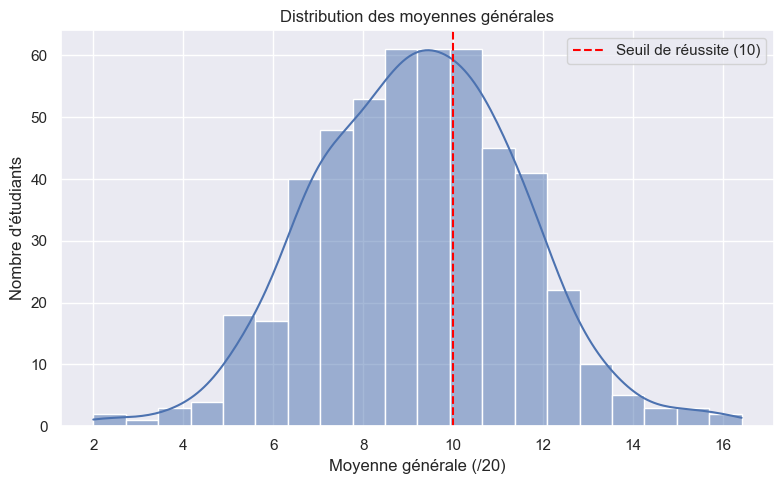

In [5]:
plt.figure(figsize=(8, 5))
sns.histplot(df["moyenne"], bins=20, kde=True)
plt.axvline(10, color="red", linestyle="--", label="Seuil de réussite (10)")
plt.title("Distribution des moyennes générales")
plt.xlabel("Moyenne générale (/20)")
plt.ylabel("Nombre d'étudiants")
plt.legend()
plt.tight_layout()
plt.savefig("../figures/histogramme.png", dpi=150)
plt.show()

### 5.2 Moyenne par filière

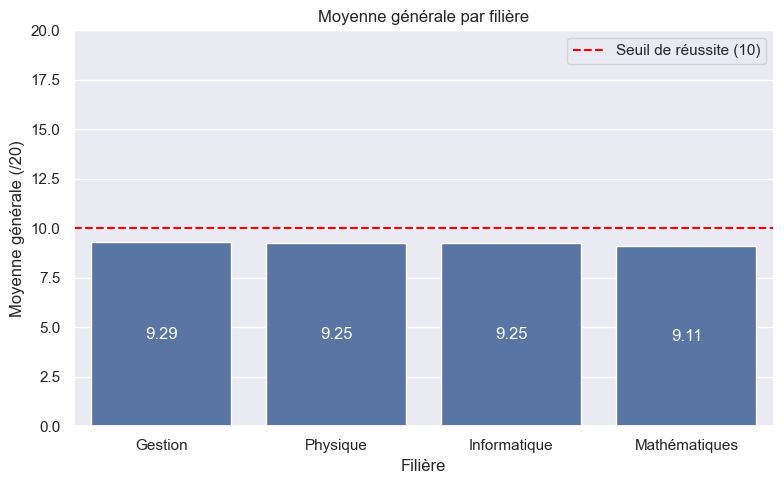

In [6]:
moy_filiere = df.groupby("filiere")["moyenne"].mean().sort_values(ascending=False).reset_index()

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=moy_filiere, x="filiere", y="moyenne")
ax.bar_label(ax.containers[0], fmt="%.2f", label_type="center", color="white")
plt.axhline(10, color="red", linestyle="--", label="Seuil de réussite (10)")
plt.ylim(0, 20)
plt.title("Moyenne générale par filière")
plt.xlabel("Filière")
plt.ylabel("Moyenne générale (/20)")
plt.legend()
plt.tight_layout()
plt.savefig("../figures/barplot_filiere.png", dpi=150)
plt.show()

### 5.3 Notes selon le niveau (boxplot)

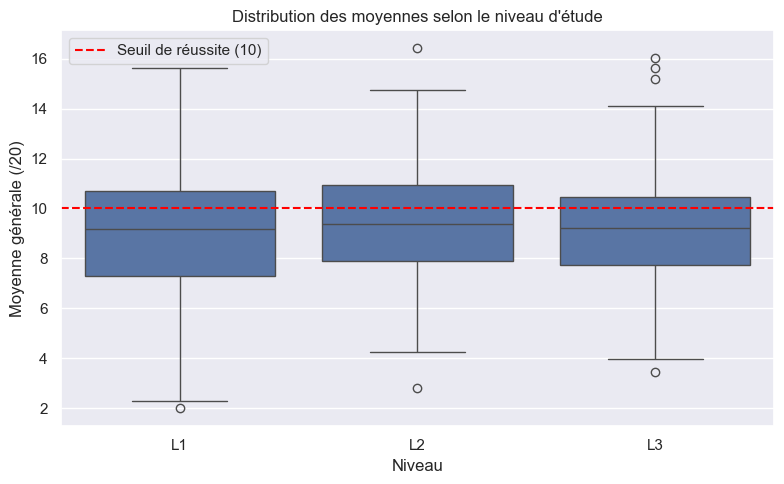

In [7]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="niveau", y="moyenne", order=["L1", "L2", "L3"])
plt.axhline(10, color="red", linestyle="--", label="Seuil de réussite (10)")
plt.title("Distribution des moyennes selon le niveau d'étude")
plt.xlabel("Niveau")
plt.ylabel("Moyenne générale (/20)")
plt.legend()
plt.tight_layout()
plt.savefig("../figures/boxplot.png", dpi=150)
plt.show()

### 5.4 Heures d'étude et moyenne

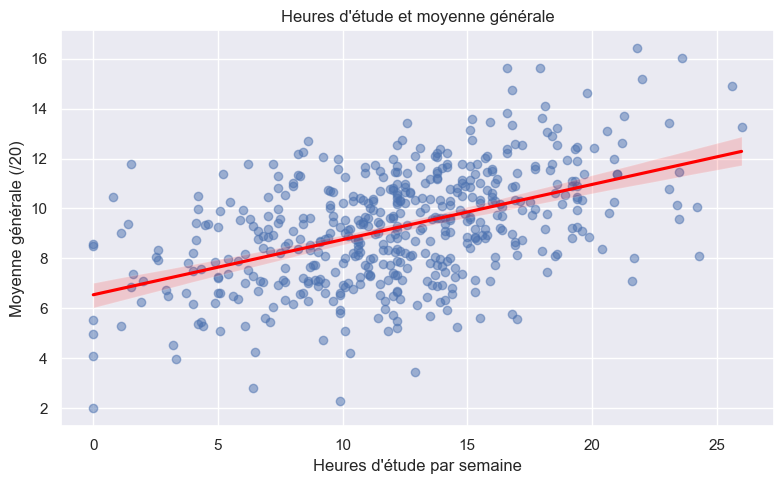

In [8]:
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x="heures_etude", y="moyenne",
            scatter_kws={"alpha": 0.5}, line_kws={"color": "red"})
plt.title("Heures d'étude et moyenne générale")
plt.xlabel("Heures d'étude par semaine")
plt.ylabel("Moyenne générale (/20)")
plt.tight_layout()
plt.savefig("../figures/scatterplot.png", dpi=150)
plt.show()

### 5.5 Absences et moyenne

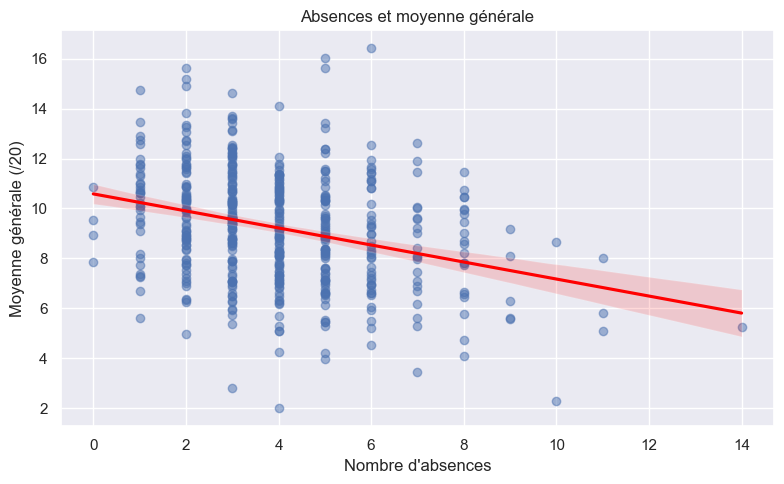

In [9]:
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x="absences", y="moyenne",
            scatter_kws={"alpha": 0.5}, line_kws={"color": "red"})
plt.title("Absences et moyenne générale")
plt.xlabel("Nombre d'absences")
plt.ylabel("Moyenne générale (/20)")
plt.tight_layout()
plt.savefig("../figures/scatterplot_absences.png", dpi=150)
plt.show()

### 5.6 Corrélations entre variables numériques

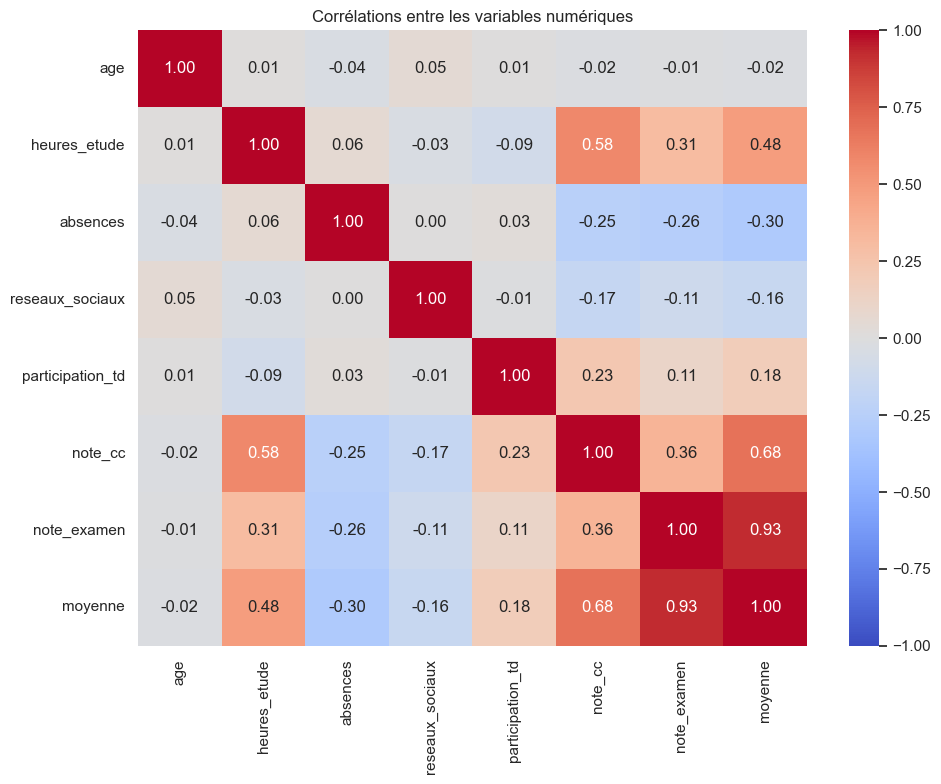

In [10]:
num = df.select_dtypes(include="number").drop(columns=["id_etudiant"])

plt.figure(figsize=(10, 8))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Corrélations entre les variables numériques")
plt.tight_layout()
plt.savefig("../figures/heatmap.png", dpi=150)
plt.show()

## Conclusion
L'analyse porte sur 500 étudiants. La moyenne générale est de 9,22/20 et le taux de réussite de 37,4 %. Les moyennes ne varient presque pas selon la filière, le sexe ou le niveau (écarts de 0,2 à 0,4 point), alors que deux variables sont nettement liées à la moyenne : les heures d'étude (corrélation de 0,48, un gain d'environ 0,2 point par heure) et les absences (corrélation de -0,30, une baisse d'environ 0,3 point par absence). Ces liens sont des tendances d'ensemble, pas des preuves de causalité, et le nuage de points reste dispersé autour des droites. Ces constats serviront de point de départ au modèle prédictif.